In [ ]:
import pathlib
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

dataset_url = (
    "https://storage.googleapis.com/download.tensorflow.org/"
    "example_images/flower_photos.tgz"
)

archive = tf.keras.utils.get_file(
    fname="flower_photos.tgz",
    origin=dataset_url,
    extract=True,
)

data_dir = pathlib.Path(archive).with_suffix("")

# The archive may contain an inner folder named "flower_photos".
if (data_dir / "flower_photos").is_dir():
    data_dir = data_dir / "flower_photos"

print("Data folder:", data_dir)
print("Class folders:", sorted(
    folder.name for folder in data_dir.iterdir() if folder.is_dir()
))

Data folder: /root/.keras/datasets/flower_photos_extracted/flower_photos
Class folders: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


In [ ]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=(224, 224),
    batch_size=32,
    label_mode="int",
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=(224, 224),
    batch_size=32,
    label_mode="int",
)

class_names = train_ds.class_names
print("Classes:", class_names)
print("Number of classes:", len(class_names))

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)

Found 3670 files belonging to 5 classes.
Using 2936 files for training.
Found 3670 files belonging to 5 classes.
Using 734 files for validation.
Classes: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
Number of classes: 5


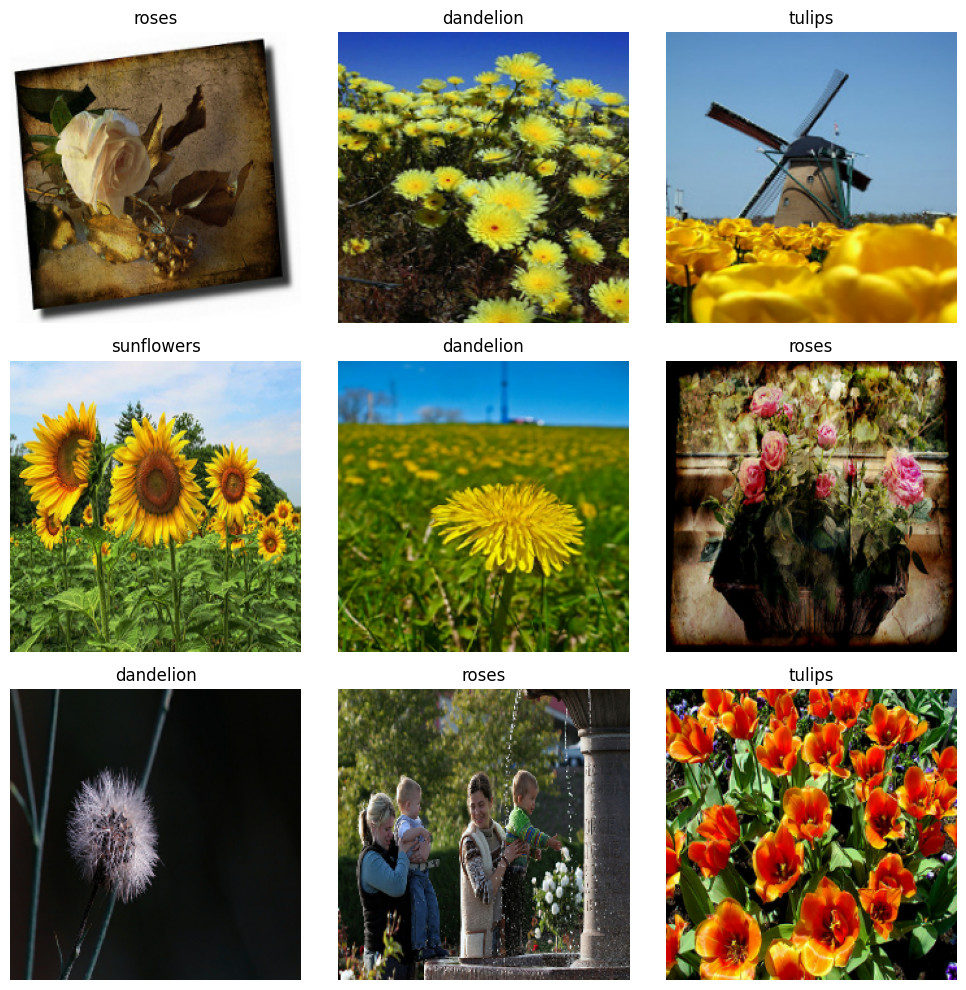

In [ ]:
plt.figure(figsize=(10, 10))

for images, labels in train_ds.take(1):
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        label = int(labels[i].numpy())
        plt.title(class_names[label])
        plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet",
)

base_model.trainable = False

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(224, 224, 3)),
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.Rescaling(1.0 / 127.5, offset=-1),
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(len(class_names), activation="softmax"),
])

print("Model output shape:", model.output_shape)
model.summary()

Model output shape: (None, 5)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_1 (RandomFlip)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │         6,405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,264,389 (8.64 MB)

 Trainable params: 6,405 (25.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

history = model.fit(
    train_ds,
    epochs=5,
    validation_data=val_ds,
    verbose=1,
)

Epoch 1/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 177s 2s/step - accuracy: 0.7091 - loss: 0.7910 - val_accuracy: 0.8515 - val_loss: 0.4358
Epoch 2/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 191s 2s/step - accuracy: 0.8556 - loss: 0.4129 - val_accuracy: 0.8801 - val_loss: 0.3576
Epoch 3/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 230s 2s/step - accuracy: 0.8835 - loss: 0.3408 - val_accuracy: 0.8883 - val_loss: 0.3302
Epoch 4/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 188s 2s/step - accuracy: 0.8951 - loss: 0.2918 - val_accuracy: 0.8978 - val_loss: 0.3083
Epoch 5/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 174s 2s/step - accuracy: 0.9159 - loss: 0.2532 - val_accuracy: 0.8978 - val_loss: 0.3025


Validation accuracy: 0.8978
Validation loss: 0.3025


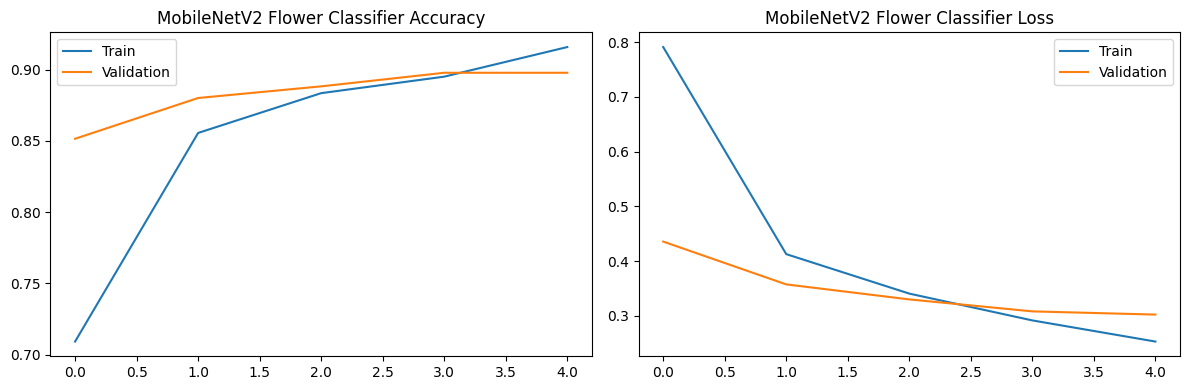

In [ ]:
val_loss, val_accuracy = model.evaluate(val_ds, verbose=0)

print("Validation accuracy:", round(val_accuracy, 4))
print("Validation loss:", round(val_loss, 4))

def plot_training(history, title):
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(history.history["accuracy"], label="Train")
    plt.plot(history.history["val_accuracy"], label="Validation")
    plt.title(f"{title} Accuracy")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history.history["loss"], label="Train")
    plt.plot(history.history["val_loss"], label="Validation")
    plt.title(f"{title} Loss")
    plt.legend()

    plt.tight_layout()
    plt.show()

plot_training(history, "MobileNetV2 Flower Classifier")

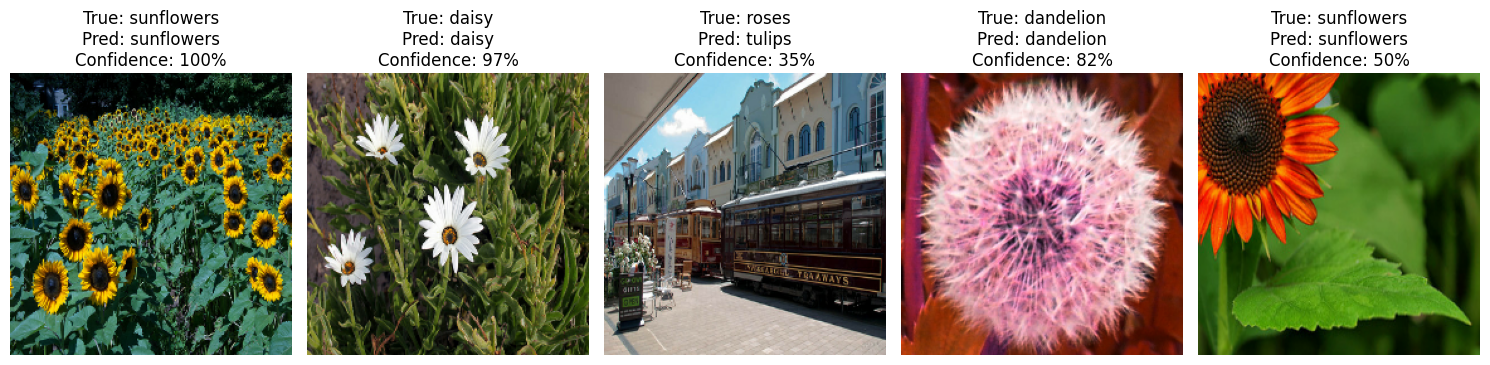

In [ ]:
images, labels = next(iter(val_ds))
probabilities = model.predict(images, verbose=0)

plt.figure(figsize=(15, 4))

for i in range(5):
    true_label = class_names[int(labels[i].numpy())]
    predicted_index = int(np.argmax(probabilities[i]))
    predicted_label = class_names[predicted_index]
    confidence = float(np.max(probabilities[i]))

    plt.subplot(1, 5, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(
        f"True: {true_label}\n"
        f"Pred: {predicted_label}\n"
        f"Confidence: {confidence:.0%}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()